# Iris Flower Classification — Complete ML Project

Run the cells from top to bottom. This notebook covers dataset exploration, visualizations, PCA, model training, evaluation, and saving the trained model for the Streamlit app.

In [2]:
# 1. Import Libraries

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import joblib

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)


In [3]:
# 2. Load Dataset

iris = load_iris()
features = iris.feature_names

df = pd.DataFrame(iris.data, columns=features)
df["species"] = [iris.target_names[i] for i in iris.target]

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())


Dataset loaded successfully!
Dataset shape: (150, 5)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [4]:
# 3. Dataset Overview

print("Dataset information:")
df.info()

print("\\nMissing values in each column:")
display(df.isnull().sum())

print("\\nStatistical summary:")
display(df.describe())

print("\\nSpecies counts:")
display(df["species"].value_counts())


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB
\nMissing values in each column:


sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

\nStatistical summary:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


\nSpecies counts:


species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

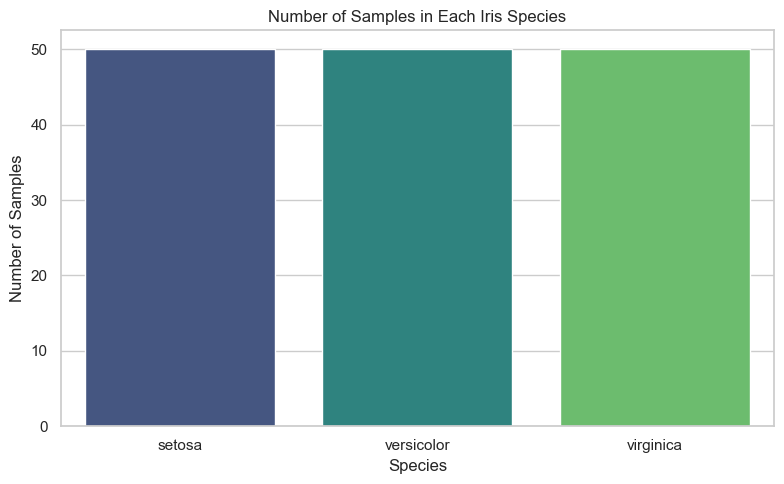

In [5]:
# 4. Species Distribution

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="species", hue="species", palette="viridis", legend=False)
plt.title("Number of Samples in Each Iris Species")
plt.xlabel("Species")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()


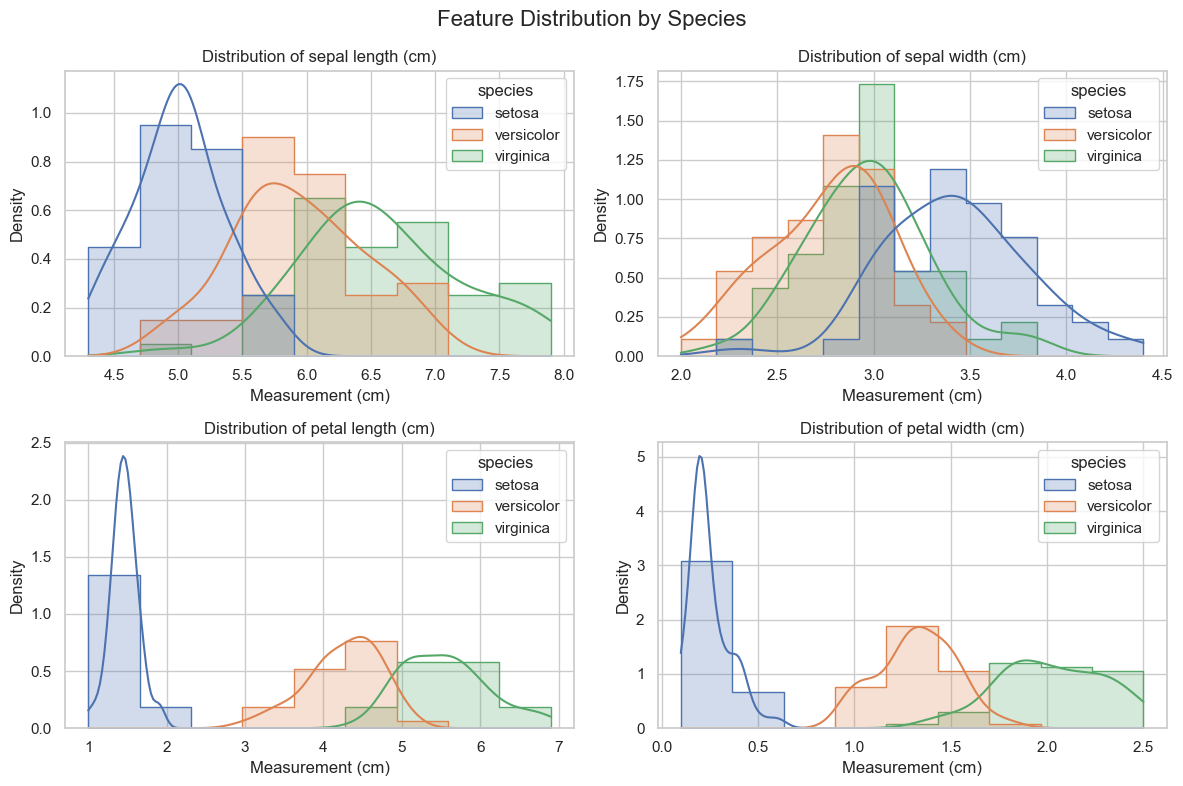

In [6]:
# 5. Feature Distributions

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for ax, feature in zip(axes, features):
    sns.histplot(data=df, x=feature, hue="species", kde=True,
                 element="step", stat="density", common_norm=False, ax=ax)
    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel("Measurement (cm)")

plt.suptitle("Feature Distribution by Species", fontsize=16)
plt.tight_layout()
plt.show()


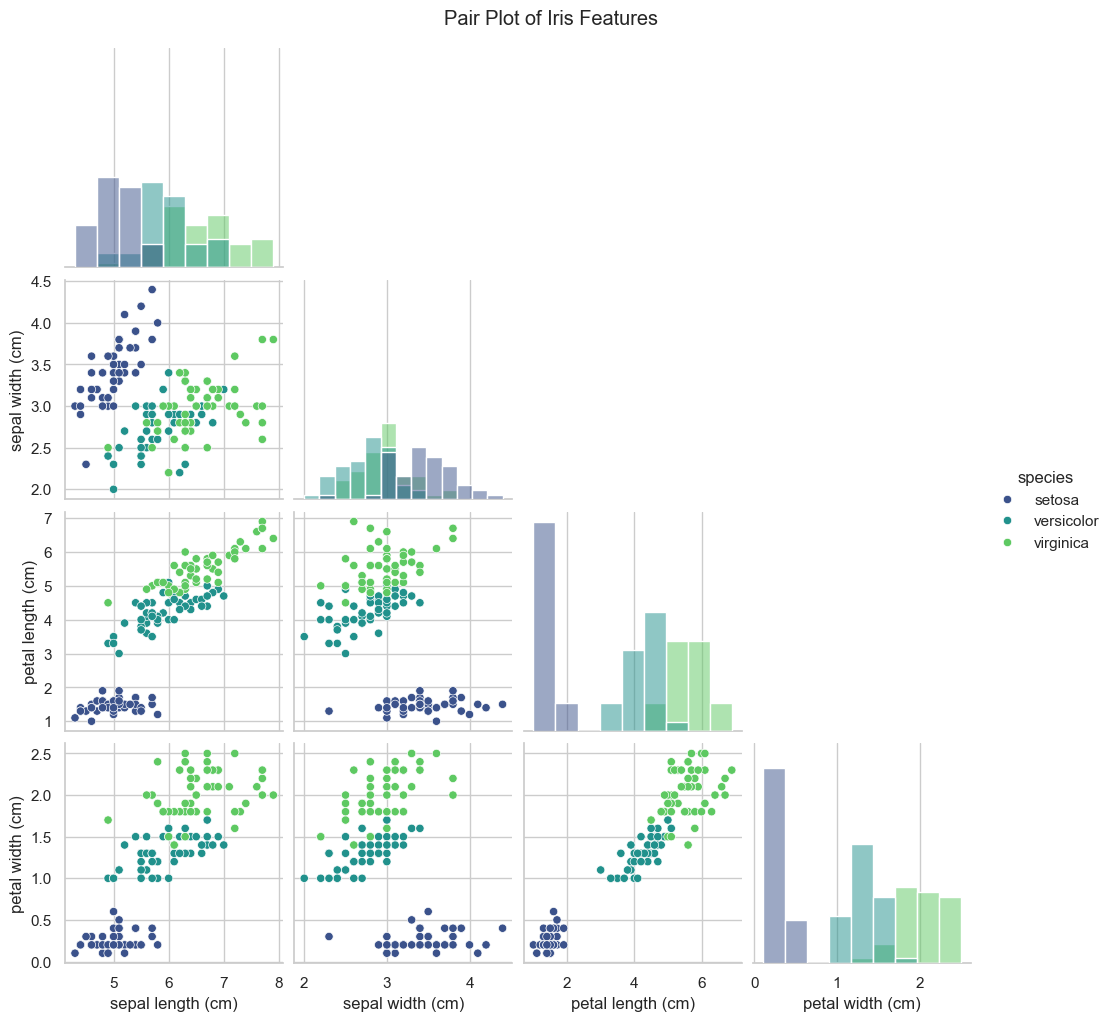

In [8]:
# 6. Pair Plot — Relationship Between Features

pair_plot = sns.pairplot(
    df,
    hue="species",
    diag_kind="hist",
    corner=True,
    palette="viridis"
)
pair_plot.fig.suptitle("Pair Plot of Iris Features", y=1.02)
plt.show()

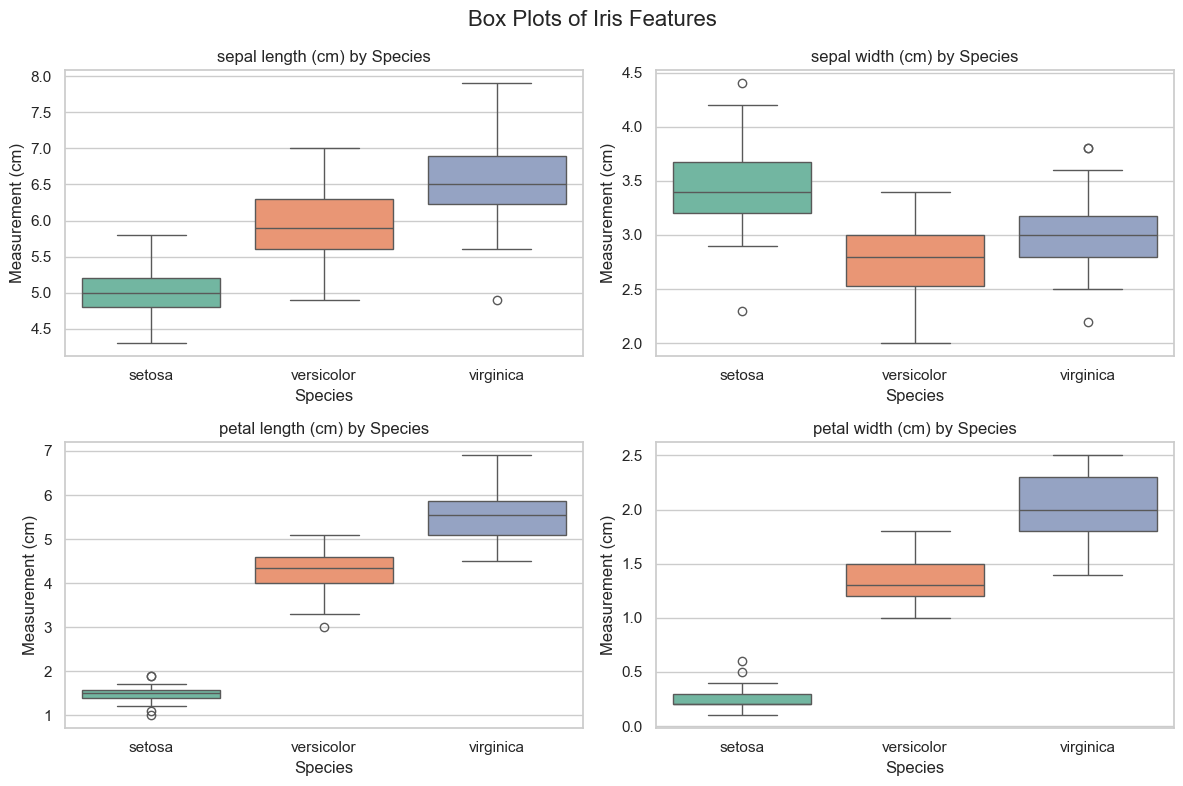

In [9]:
# 7. Box Plots — Compare Feature Ranges and Outliers

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for ax, feature in zip(axes, features):
    sns.boxplot(data=df, x="species", y=feature, hue="species",
                palette="Set2", legend=False, ax=ax)
    ax.set_title(f"{feature} by Species")
    ax.set_xlabel("Species")
    ax.set_ylabel("Measurement (cm)")

plt.suptitle("Box Plots of Iris Features", fontsize=16)
plt.tight_layout()
plt.show()


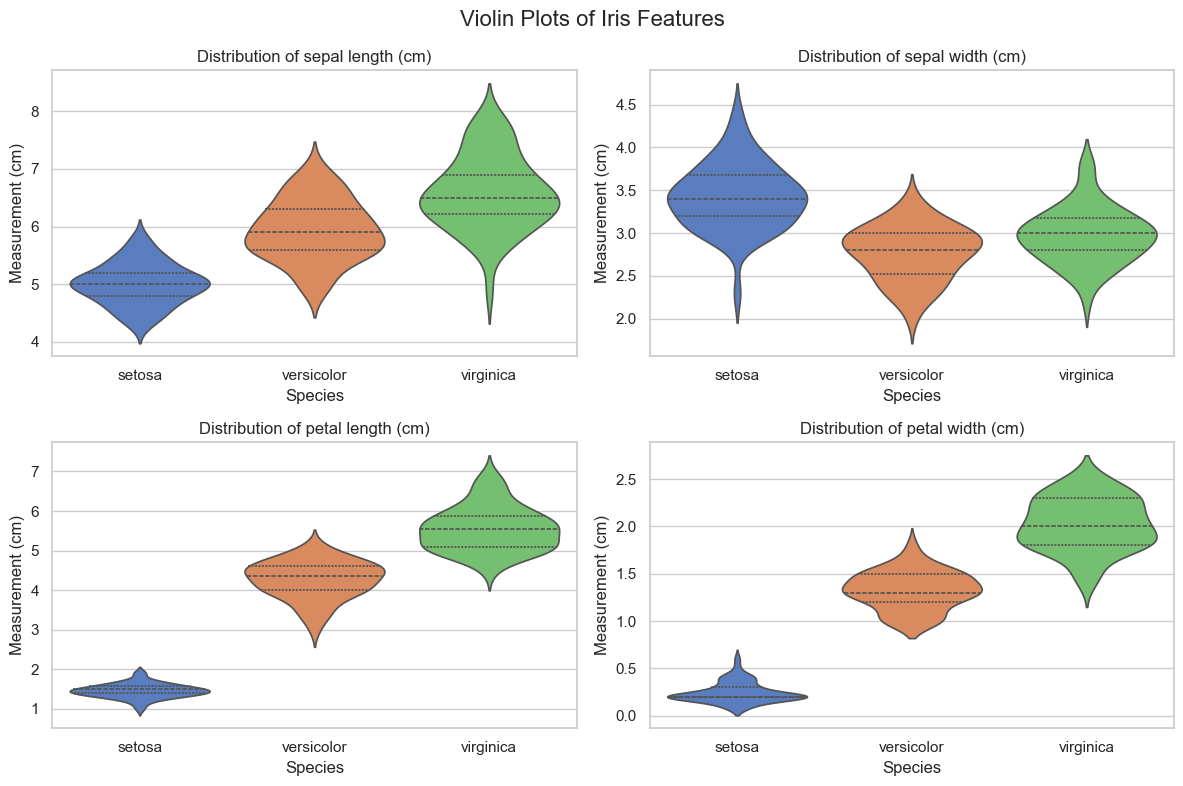

In [10]:
# 8. Violin Plots — Feature Distribution Shape

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for ax, feature in zip(axes, features):
    sns.violinplot(data=df, x="species", y=feature, hue="species",
                   palette="muted", inner="quartile", legend=False, ax=ax)
    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel("Species")
    ax.set_ylabel("Measurement (cm)")

plt.suptitle("Violin Plots of Iris Features", fontsize=16)
plt.tight_layout()
plt.show()


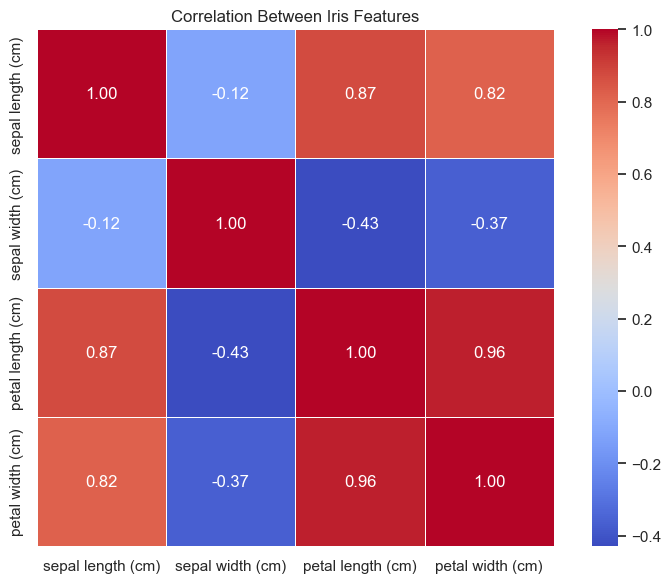

In [11]:
# 9. Correlation Heatmap

correlation = df[features].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, cmap="coolwarm",
            fmt=".2f", linewidths=0.5, square=True)
plt.title("Correlation Between Iris Features")
plt.tight_layout()
plt.show()


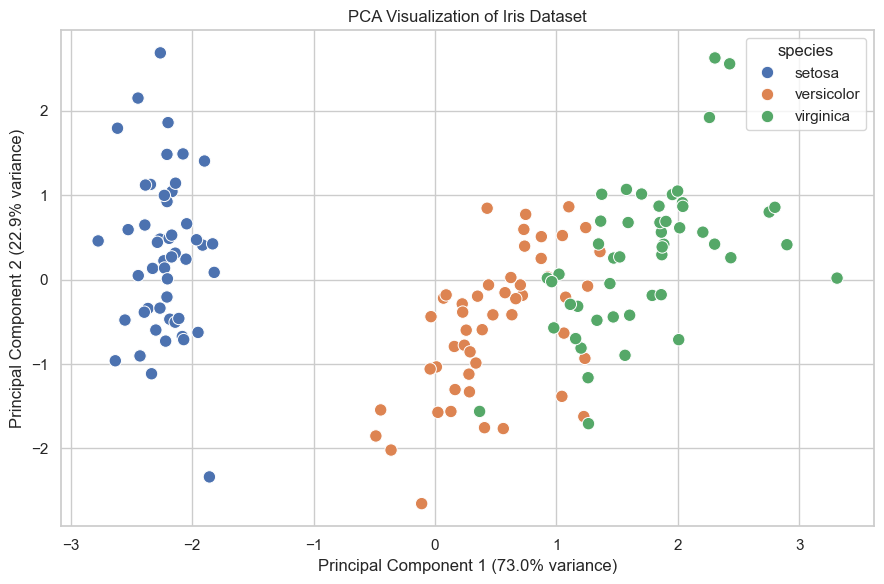

Total variance explained by 2 components: 95.81%


In [12]:
# 10. PCA — Reduce Features to 2 Dimensions for Visualization

scaler = StandardScaler()
scaled_features = scaler.fit_transform(df[features])

pca = PCA(n_components=2)
pca_values = pca.fit_transform(scaled_features)

pca_df = pd.DataFrame(pca_values, columns=["PC1", "PC2"])
pca_df["species"] = df["species"]

variance = pca.explained_variance_ratio_ * 100

plt.figure(figsize=(9, 6))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="species",
                palette="deep", s=80)
plt.title("PCA Visualization of Iris Dataset")
plt.xlabel(f"Principal Component 1 ({variance[0]:.1f}% variance)")
plt.ylabel(f"Principal Component 2 ({variance[1]:.1f}% variance)")
plt.tight_layout()
plt.show()

print(f"Total variance explained by 2 components: {variance.sum():.2f}%")


In [13]:
# 11. Prepare Data for Machine Learning

X = df[features]
y = df["species"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 120
Testing samples: 30


In [14]:
# 12. Train Random Forest Classifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)
y_pred = rf_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"Test Accuracy: {accuracy * 100:.2f}%")


Test Accuracy: 90.00%


In [15]:
# 13. Stratified 5-Fold Cross Validation

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_scores = cross_val_score(
    RandomForestClassifier(n_estimators=100, random_state=42),
    X, y, cv=cv, scoring="accuracy"
)

print("Cross-validation scores:", np.round(cv_scores, 4))
print(f"Mean CV accuracy: {cv_scores.mean() * 100:.2f}%")
print(f"Standard deviation: {cv_scores.std() * 100:.2f}%")


Cross-validation scores: [0.9667 0.9667 0.9333 0.9667 0.9   ]
Mean CV accuracy: 94.67%
Standard deviation: 2.67%


In [16]:
# 14. Classification Report

print(classification_report(y_test, y_pred, zero_division=0))


              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



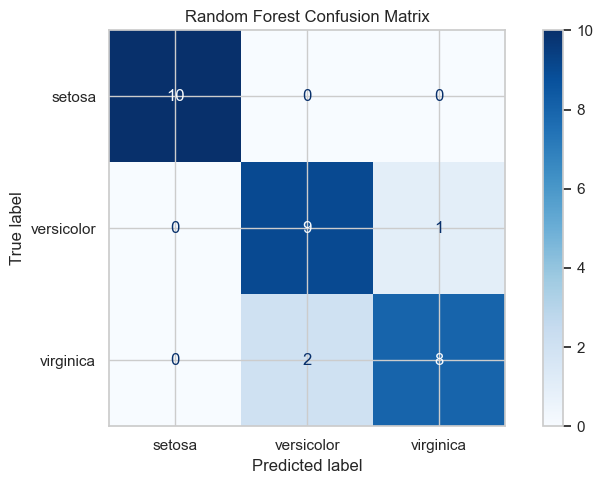

In [17]:
# 15. Confusion Matrix

cm = confusion_matrix(y_test, y_pred, labels=rf_model.classes_)

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=rf_model.classes_
)
display_matrix.plot(cmap="Blues", values_format="d")
plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()


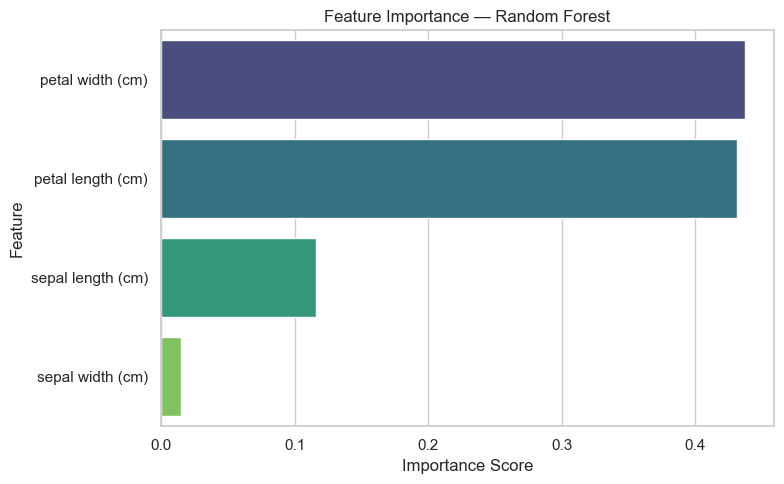

,Feature,Importance
3,petal width (cm),0.437185
2,petal length (cm),0.431466
0,sepal length (cm),0.116349
1,sepal width (cm),0.015000


In [18]:
# 16. Feature Importance

importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": rf_model.feature_importances_
}).sort_values(by="Importance", ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=importance_df, x="Importance", y="Feature",
            hue="Feature", palette="viridis", legend=False)
plt.title("Feature Importance — Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

display(importance_df)


In [19]:
# 17. Save Trained Model

model_filename = "iris_rf_model.joblib"
joblib.dump(rf_model, model_filename)

print(f"Model saved successfully as: {model_filename}")


Model saved successfully as: iris_rf_model.joblib


In [20]:
# 18. Test Prediction Function

def predict_new_flower(sepal_length, sepal_width, petal_length, petal_width):
    input_data = pd.DataFrame(
        [[sepal_length, sepal_width, petal_length, petal_width]],
        columns=features
    )

    prediction = rf_model.predict(input_data)[0]
    probabilities = rf_model.predict_proba(input_data)[0]
    confidence = probabilities.max() * 100

    return prediction, confidence

species, confidence = predict_new_flower(5.1, 3.5, 1.4, 0.2)

print("Predicted species:", species)
print(f"Model probability for predicted class: {confidence:.2f}%")


Predicted species: setosa
Model probability for predicted class: 100.00%
